# Laboratory Activity 3
# Predicting Car Fuel Efficiency Using Linear Regression

**Objective:** Build a Linear Regression model to predict a car's fuel efficiency (MPG) based on its weight using a real-world dataset.

## Real-World Scenario
You are a Data Analyst at **CarHub Philippines**. Your company wants to estimate the fuel efficiency of vehicles based on their weight. This helps customers compare vehicles and assists manufacturers in designing more fuel-efficient cars.

## Learning Outcomes
- Load a real-world dataset
- Visualize the relationship between variables
- Train a Linear Regression model
- Interpret θ₀ and θ₁
- Evaluate the model using RMSE and R²

## Step 1. Import Libraries

In [95]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score

## Step 2. Load the Dataset

In [96]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
df = pd.read_csv(url)
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [97]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


### Guide Questions
- How many rows are in the dataset?

There are around 398 rows in the dataset.

- Which column is your feature?

The weight is the feature or the input variable.

- Which column is your target?

The fuel efficiency (measured as miles per gallon or mpg) is the target or the output variable.

## Step 3. Clean the Data

In [98]:
df = df[['weight','mpg']].dropna()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   weight  398 non-null    int64  
 1   mpg     398 non-null    float64
dtypes: float64(1), int64(1)
memory usage: 6.3 KB


## Step 4. Visualize the Data

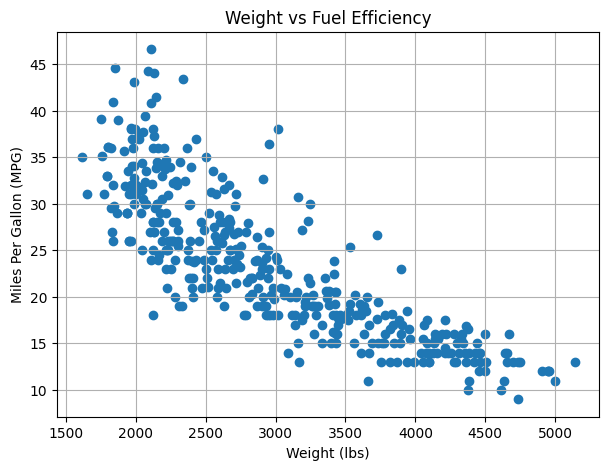

In [99]:
plt.figure(figsize=(7,5))
plt.scatter(df['weight'], df['mpg'])
plt.xlabel("Weight (lbs)")
plt.ylabel("Miles Per Gallon (MPG)")
plt.title("Weight vs Fuel Efficiency")
plt.grid(True)
plt.show()

### Guide Questions
- Describe the relationship between weight and MPG.

The relationship between weight and MPG can be described as negative correlation or an inverse relationship. The trend of the figure shows that as the weight of the car increases while the fuel efficiency drops significantly.

- Is Linear Regression appropriate? Why?

Yes, Linear Regression is appropriate for this model as there is a linear relationship between the two variables and the aim here is to predict the fuel efficiency measured in numerical values, which the linear regression does.

## Step 5. Prepare the Data

In [100]:
x=df[['weight']]
y=df["mpg"]

## Step 6. Split the Dataset

In [101]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
print(len(x_train),len(x_test))

318 80


## Step 7. Train the Model

In [102]:
model = LinearRegression()
model.fit(x_train,y_train)
print("Training Complete")

Training Complete


## Step 8. Display θ₀ and θ₁

In [103]:
print("Intercept (θ₀):", model.intercept_)
print("Slope (θ₁):", model.coef_[0])

Intercept (θ₀): 46.78206336645047
Slope (θ₁): -0.007805242351594879


### Guide Questions
- What does θ₀ represent?

The θ₀ represents the Intercept is the expected value of target when feature is exactly 0 serving as the baseline value.

- What does θ₁ represent?

The θ₁ represents the Slope (Coefficient) or how much the target value change as the feature value increases by exactly 1 unit. It represents the direction or the trend of the prediction.

## Step 9. Make Predictions

In [104]:
predictions = model.predict(x_test)
predictions[:10]

array([32.77165335, 26.29330219, 26.22305501, 16.0294085 , 13.71125152,
       30.39105443, 24.42004403,  9.82424083, 15.09277942, 24.34199161])

## Step 10. Evaluate the Model

In [105]:
rmse = root_mean_squared_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("RMSE:", rmse)
print("R²:", r2)

RMSE: 3.859386099451077
R²: 0.722971057303075


## Step 11. Plot the Regression Line

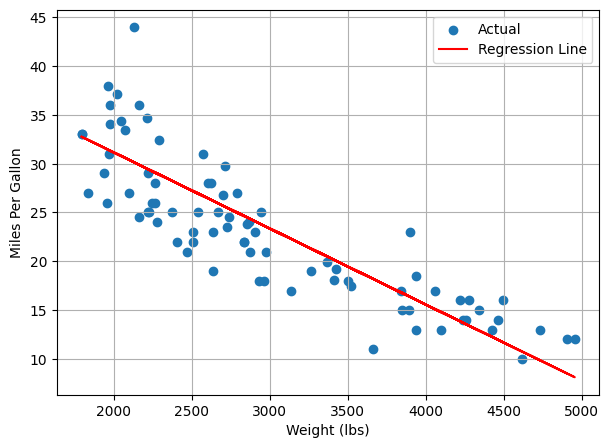

In [106]:
plt.figure(figsize=(7,5))
plt.scatter(x_test, y_test, label='Actual')
plt.plot(x_test, predictions, color='red', label='Regression Line')
plt.xlabel("Weight (lbs)")
plt.ylabel("Miles Per Gallon")
plt.legend()
plt.grid(True)
plt.show()

- Based on the graph, describe the relationship between a car's weight and its fuel efficiency (MPG)

Similarly to the scatter plot earlier and the projected regression line, there is still a negative correlation due to the downward slope trajectory between the car's weight and its fuel efficiency where the MPG drops significantly when more weight is added.

- Does this graph suggest that weight is the only factor affecting fuel efficiency? Explain.

No, but it is one of the main leading factory that affects fuel efficiency. As seen in the graph, the vertical spread or variance indicates that there may be other factors that can increase the accuracy of this model.

## Step 12. Predict New Cars

In [107]:
new_car = pd.DataFrame({"weight": [1690, 4269, 3253, 2134, 2999]})

prediction = model.predict(new_car)
for weight, pred in zip(new_car['weight'], prediction):
    print(f"{weight}: {pred.round(2)}")

1690: 33.59
4269: 13.46
3253: 21.39
2134: 30.13
2999: 23.37


# Reflection Questions

1. What problem does this model solve?

The model aims to predict the fuel efficiency of a given car based on their given weight. The model utilized a Linear Regression due to the nature of the dataset where the features are inversely proportional to the target.

2. Why is this supervised learning?

Linear Regression is classified as supervised learning due to the nature of the getting an answer or output. Supervised learnings aims to get a specific correct answer which the linear regression provides through a numerical format. Lastly, both the input feature (weight) and the known target outcome (mpg) were provided during training so the model could learn the mapping between them.

3. What are the feature and target variables?

The feature variable is the weight (x) while the target variable is the fuel efficiency (y) or also known as the miles per gallon (MPG).

4. Interpret θ₀.

If a car has a weight of exactly 0, the model predicts that the target variable will be 46.78. This represents the theoretical baseline MPG of a hypothetical vehicle with a weight of 0 unit.

5. Interpret θ₁.

For every 1 additional unit of weight that is added to the car, the target variable drops by an additional 0.0078 units since the value is negative.

6. Explain the RMSE.

On average, the model's predictions miss the true actual values by about 3.86 units. Since the target variable is Miles Per Gallon (MPG), it means that the predictions are usually off by about 3.86 MPG. A lower RMSE means the model's predictions are closer, on average, to actual vehicle MPG values.

7. Explain the R².

The R² with the value of 0.722971057303075 or as 72.3% represents the variation in the target data. This means that by looking only at the car's weight, the model can successfully account for nearly three-quarters of the differences in the target variable. The remaining 27.7% of the variation is missing information likely due to factors the model did not consider such as displacement, horsepower, or acceleration.

8. Give two companies that could benefit from this model.

Mitsubishi & Toyota can heavily benefit from this type of model as both are the leading automotive companies locally. Fuel efficiency is a top-priority with the rising prices of petroleum and prioritizing this feature helps to maximize future car model iterations.

9. Suggest one way to improve the model.

Since the model just utilized the weight to predict the fuel efficiency. Other features could have been utilized as well to improve the accuracy even more towards the prediction of the fuel efficiency. This is supported by the 72.3% of the variation in the target data which could be vastly improved by taking the other features into consideration.